# 1. Libraries

In [8]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import fft

matplotlib.rcParams['font.family']     = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size']       = 12
matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42
matplotlib.rcParams['axes.titlesize']  = 12
matplotlib.rcParams['axes.labelsize']  = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12

# 2. Functions

In [9]:
def LowPass_Filter(Freq_, Amp1_, Tau1_):
    return Amp1_ / (1 + 1j * Freq_ * Tau1_)


def LowPass_Butterworth(Freq_, Amp1_, Tau1_, n_order):
    return Amp1_ / np.sqrt(1 + (Tau1_ * Freq_) ** (2 * n_order))


def HighPass_Butterworth(Freq_, Amp1_, Tau1_, n_order):
    return Amp1_ / np.sqrt(1 + (Tau1_ * Freq_ + np.spacing(1)) ** (-2 * n_order))


def BandPass_Butterworth(Freq_, B_, w0, n_order):
    return 1 / np.sqrt(1 + ((Freq_ ** 2 - w0 ** 2) / (B_ * Freq_ + np.spacing(1))) ** (2 * n_order))

# 3. Plots

## 3.0 Parameters

In [26]:
T  = 300.0
dt = 0.001
t  = np.arange(-T, T, dt)
n  = t.size
dt = t[1] - t[0]

## Power-law Power spectrum

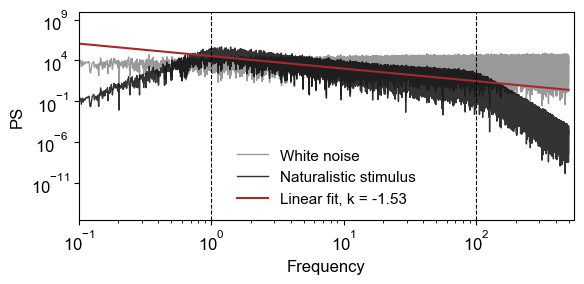

In [44]:
Signal  = np.random.normal(loc=0, scale=0.1, size=n)
Signal_ = fft.fft(Signal)
Freq    = fft.fftshift(fft.fftfreq(n=n, d=dt))

Tau1, Tau2, Tau3 = 0.01, 20., 100.
Amp1, Amp2, Amp3 = 0.1, 100, 0

Filter1_ = LowPass_Filter(Freq, Amp1, Tau1)
Filter2_ = LowPass_Filter(Freq, Amp2, Tau2)
Filter3_ = LowPass_Filter(Freq, Amp3, Tau3)

n_order = 4;  WL = 1;  WH = 100;  B = WH - WL;  w0 = np.sqrt(WH * WL)
Filter_bandpass_Butterworth = BandPass_Butterworth(Freq, B, w0, n_order)

SignalF1_ = Filter_bandpass_Butterworth * (Filter1_ + Filter2_ + Filter3_) * fft.fftshift(Signal_)
PowerSpec = SignalF1_ * np.conjugate(SignalF1_)

PowerSpec_gaussian = fft.fftshift(Signal_) * np.conjugate(fft.fftshift(Signal_))

idx_fit_min = np.where(Freq > WL)[0][0]
idx_fit_max = np.where(Freq > WH)[0][0]
idx_fit     = np.where(Freq > 0)[0][0]
fit_pars    = np.polyfit(
    np.log(Freq[idx_fit_min:idx_fit_max] + np.spacing(1)),
    np.log(PowerSpec[idx_fit_min:idx_fit_max] + np.spacing(1)), 1)

Fig, ax = plt.subplots(1, figsize=(6, 3))
ax.plot(Freq[idx_fit:], PowerSpec_gaussian[idx_fit:], alpha=0.8, color='Grey', label='White noise', linewidth = 1)
ax.plot(Freq[idx_fit:], PowerSpec[idx_fit:], alpha=0.8, color='k', label='Naturalistic stimulus', linewidth = 1)
ax.plot(Freq[idx_fit:], np.exp(fit_pars[0] * np.log(Freq[idx_fit:]) + fit_pars[1]),
        color='brown', label='Linear fit, k = ' + str(np.round(np.real(fit_pars[0]), decimals=2)))
ax.axvline(x=WL, color='k', linestyle='--', linewidth=0.8)
ax.axvline(x=WH, color='k', linestyle='--', linewidth=0.8)
ax.set_xlim(0.1, 550)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_xlabel('Frequency', fontsize=12)
ax.set_ylabel('PS', fontsize=12)
ax.tick_params(labelsize=12)
ax.legend(ncol=1, loc=8, fontsize=11, frameon=False)
plt.tight_layout()
plt.show()

## 3.2 Slope as a function of time scales

In [55]:
Signal  = np.random.normal(loc=0, scale=2, size=n)
Signal_ = fft.fft(Signal)
Freq    = fft.fftshift(fft.fftfreq(n=n, d=dt))

Amp1       = 0.1
Tau1       = 0.01
Tau2_array = np.round(np.arange(1, 100, 5), decimals=1)
Amp2_array = np.array([100])
Tau3, Amp3 = np.array([100, 0])
N_tau2     = Tau2_array.size

fit_pars = np.zeros(N_tau2)
r_sq     = np.zeros(N_tau2)

counter_tau = -1
for Tau2 in Tau2_array:
    counter_tau += 1
    for Amp2 in Amp2_array:
        Filter1_ = LowPass_Filter(Freq, Amp1, Tau1)
        Filter2_ = LowPass_Filter(Freq, Amp2, Tau2)
        Filter3_ = LowPass_Filter(Freq, Amp3, Tau3)

        n_order = 4;  WL = 1.;  WH = 100;  B = WH - WL;  w0 = np.sqrt(WH * WL)
        Filter_bandpass_Butterworth = BandPass_Butterworth(Freq, B, w0, n_order)

        SignalF1_ = Filter_bandpass_Butterworth * (Filter1_ + Filter2_ + Filter3_) * fft.fftshift(Signal_)
        PowerSpec = SignalF1_ * np.conjugate(SignalF1_)
        SignalF1  = fft.ifft(fft.ifftshift(SignalF1_)).real

        idx_fit_min = np.where(Freq > WL)[0][0]
        idx_fit_max = np.where(Freq > WH)[0][0]
        (fit_pars[counter_tau], b), r_sq[counter_tau], _, _, _ = np.polyfit(
            np.log(Freq[idx_fit_min:idx_fit_max] + np.spacing(1)),
            np.log(PowerSpec[idx_fit_min:idx_fit_max] + np.spacing(1)), 1, full=True)

/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_2938/2243489566.py:32: ComplexWarning: Casting complex values to real discards the imaginary part
  (fit_pars[counter_tau], b), r_sq[counter_tau], _, _, _ = np.polyfit(


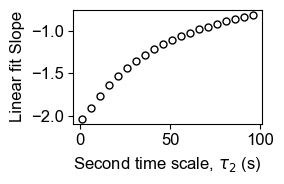

In [58]:
c    = np.arange(5, N_tau2 + 8)
norm = mpl.colors.Normalize(vmin=c.min(), vmax=c.max())
cmap = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.Blues)
cmap.set_array([])

Fig, ax = plt.subplots(1, figsize=(3, 2))
for i in range(N_tau2):
    if Tau2_array[i] == 20:
        print(fit_pars[i])
    ax.plot(Tau2_array[i], fit_pars[i], marker='o',
            color='white', markeredgecolor='k', markersize=5)
ax.set_ylabel('Linear fit Slope', fontsize=12)
ax.set_xlabel(r'Second time scale, $\tau_{2}$ (s)', fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

## 3.3 Inverse slope fitting

Target slope : -2.0
Best Tau2    : 2.113 s
Verified slope: -2.015


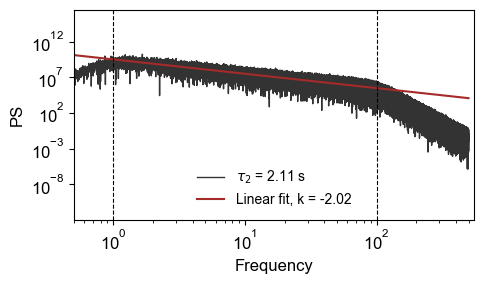

In [65]:
k_target = -2.0  # desired power-law slope

# Invert the slope curve: find Tau2 such that slope(Tau2) == k_target
slopes_real = np.real(fit_pars)
sort_idx    = np.argsort(slopes_real)
Tau2_best   = np.interp(k_target, slopes_real[sort_idx], Tau2_array[sort_idx])

print(f'Target slope : {k_target}')
print(f'Best Tau2    : {np.round(Tau2_best, 3)} s')

# Recompute power spectrum with the optimal Tau2
Filter1_best = LowPass_Filter(Freq, Amp1, Tau1)
Filter2_best = LowPass_Filter(Freq, Amp2_array[0], Tau2_best)
Filter3_best = LowPass_Filter(Freq, Amp3, Tau3)

n_order = 4;  WL = 1.;  WH = 100;  B = WH - WL;  w0 = np.sqrt(WH * WL)
Filter_bp_best = BandPass_Butterworth(Freq, B, w0, n_order)

SignalF_best = Filter_bp_best * (Filter1_best + Filter2_best + Filter3_best) * fft.fftshift(Signal_)
PowerSpec_best = np.real(SignalF_best * np.conjugate(SignalF_best))

idx_fit_min = np.where(Freq > WL)[0][0]
idx_fit_max = np.where(Freq > WH)[0][0]
idx_fit     = np.where(Freq > 0)[0][0]

pars_best = np.polyfit(
    np.log(Freq[idx_fit_min:idx_fit_max] + np.spacing(1)),
    np.log(PowerSpec_best[idx_fit_min:idx_fit_max] + np.spacing(1)), 1)

print(f'Verified slope: {np.round(np.real(pars_best[0]), 3)}')

Fig, ax = plt.subplots(1, figsize=(5, 3))
ax.plot(Freq[idx_fit:], PowerSpec_best[idx_fit:], alpha=0.8, color='k',
        label=r'$\tau_2$ = ' + str(np.round(Tau2_best, 2)) + ' s', linewidth=1)
ax.plot(Freq[idx_fit:], np.exp(pars_best[0] * np.log(Freq[idx_fit:]) + pars_best[1]),
        color='brown', linestyle='-',
        label='Linear fit, k = ' + str(np.round(np.real(pars_best[0]), 2)))
ax.axvline(x=WL, color='k', linestyle='--', linewidth=0.8)
ax.axvline(x=WH, color='k', linestyle='--', linewidth=0.8)
ax.set_xlim(0.5, 550)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_xlabel('Frequency', fontsize=12)
ax.set_ylabel('PS', fontsize=12)
ax.tick_params(labelsize=12)
ax.legend(fontsize=10, frameon=False)
plt.tight_layout()
plt.show()

Local sensitivity dk/dTau2 at Tau2_best : 0.0258
For Δk = ±0.2  →  ΔTau2 = ±7.76 s


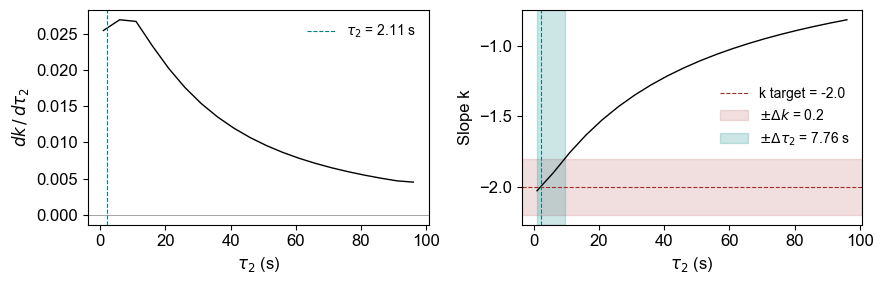

In [66]:
delta_k = 0.2  # uncertainty in the measured slope

# Numerical derivative dk/dTau2 along the forward curve
dslopes = np.gradient(slopes_real, Tau2_array)

# Local sensitivity at the optimal Tau2
sens_at_best = np.interp(Tau2_best, Tau2_array, dslopes)
delta_Tau2   = delta_k / np.abs(sens_at_best)

print(f'Local sensitivity dk/dTau2 at Tau2_best : {np.round(sens_at_best, 4)}')
print(f'For Δk = ±{delta_k}  →  ΔTau2 = ±{np.round(delta_Tau2, 2)} s')

# Tau2 bounds corresponding to k_target ± delta_k
Tau2_lo = np.interp(k_target + delta_k, slopes_real[sort_idx], Tau2_array[sort_idx])
Tau2_hi = np.interp(k_target - delta_k, slopes_real[sort_idx], Tau2_array[sort_idx])

Fig, axes = plt.subplots(1, 2, figsize=(9, 3))

# Left: sensitivity curve dk/dTau2
axes[0].plot(Tau2_array, dslopes, color='k', linewidth=1)
axes[0].axvline(x=Tau2_best, color='teal', linestyle='--', linewidth=0.8,
                label=r'$\tau_2$ = ' + str(np.round(Tau2_best, 2)) + ' s')
axes[0].axhline(y=0, color='grey', linewidth=0.5)
axes[0].set_xlabel(r'$\tau_2$ (s)', fontsize=12)
axes[0].set_ylabel(r'$dk\,/\,d\tau_2$', fontsize=12)
axes[0].tick_params(labelsize=12)
axes[0].legend(fontsize=10, frameon=False)

# Right: slope vs Tau2 with uncertainty bands
axes[1].plot(Tau2_array, slopes_real, color='k', linewidth=1)
axes[1].axhline(y=k_target, color='brown', linestyle='--', linewidth=0.8,
                label='k target = ' + str(k_target))
axes[1].axhspan(k_target - delta_k, k_target + delta_k,
                alpha=0.15, color='brown', label=r'$\pm\Delta k$ = ' + str(delta_k))
axes[1].axvline(x=Tau2_best, color='teal', linestyle='--', linewidth=0.8)
axes[1].axvspan(min(Tau2_lo, Tau2_hi), max(Tau2_lo, Tau2_hi),
                alpha=0.2, color='teal',
                label=r'$\pm\Delta\tau_2$ = ' + str(np.round(delta_Tau2, 2)) + ' s')
axes[1].set_xlabel(r'$\tau_2$ (s)', fontsize=12)
axes[1].set_ylabel('Slope k', fontsize=12)
axes[1].tick_params(labelsize=12)
axes[1].legend(fontsize=10, frameon=False)

plt.tight_layout()
plt.show()